# Read a causal calendar steering experiment

**Question.** Which edits move the answer from January toward February?

Mistral-7B's month-token activation was edited before one transformer block. The original prompt still said November. A donor prompt saying December supplied the activation difference. Each projected edit has a same-norm control. This notebook works with a small table of recorded model runs, plus a toy geometric warm-up. Full inference uses the scripts linked below. [Goodfire's Steering Along Manifolds](https://www.goodfire.com/research/manifold-steering)

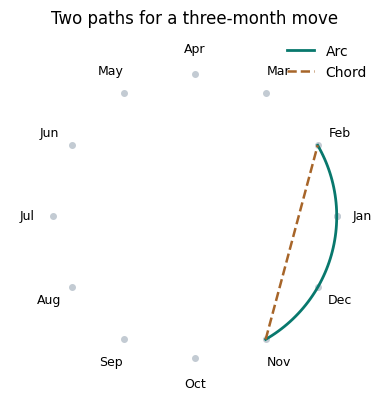

In [1]:
%matplotlib inline
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt

data_dir = Path("data") if Path("data/steering-examples.csv").is_file() else Path("notebooks/data")
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
point = np.exp(2j * np.pi * np.arange(len(month_names)) / 12)
alpha = np.linspace(0, 1, 60)
november, february = point[10], point[1]
arc = november * np.exp(1j * alpha * np.angle(february / november))
chord = (1 - alpha) * november + alpha * february

fig, ax = plt.subplots(figsize=(5.2, 4.0), layout="constrained")
ax.plot(*np.array([np.r_[point.real, point.real[0]], np.r_[point.imag, point.imag[0]]]),
        "o", color="#c3cbd3", markersize=4)
ax.plot(arc.real, arc.imag, lw=2, color="#08786d", label="Arc")
ax.plot(chord.real, chord.imag, "--", lw=1.8, color="#a76529", label="Chord")
for z, name in zip(1.18 * point, month_names, strict=True):
    ax.text(z.real, z.imag, name, fontsize=9, ha="center", va="center")
ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), title="Two paths for a three-month move")
ax.set_aspect("equal")
ax.axis("off")
ax.legend(frameon=False, loc="upper right")
plt.show()

## Compare the actual November edits

The model saw *Let's do some calendar math. Two months from November is*. Its unedited answer was January. We compare the full-vocabulary probability of February across edits. The 11-dimensional PCA and random controls each use the same perturbation norm as the 11-dimensional calendar edit.

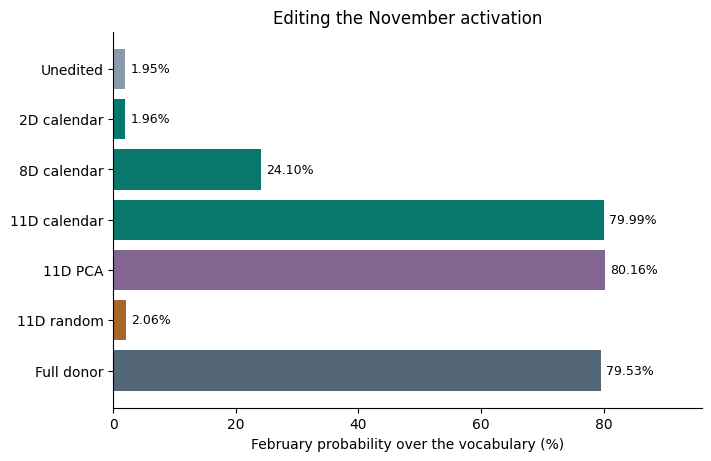

In [2]:
with (data_dir / "steering-examples.csv").open(newline="") as stream:
    pairs = list(csv.DictReader(stream))
exact = {(r["condition"], int(r["dimensions"])): r for r in pairs
         if (r["source_month"], r["style"], r["offset"], r["donor_shift"]) == ("November", "paper", "2", "1")}

names = ["Unedited", "2D calendar", "8D calendar", "11D calendar", "11D PCA", "11D random", "Full donor"]
keys = [("harmonics", 2), ("harmonics", 8), ("harmonics", 11), ("pca", 11), ("random", 11), ("full_donor", 4096)]
baseline = float(exact[keys[0]]["baseline_target_probability"])
values = 100 * np.array([baseline] + [float(exact[key]["target_probability"]) for key in keys])
fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
bars = ax.barh(names, values, color=["#8b9aad", "#08786d", "#08786d", "#08786d", "#826591", "#a76529", "#546777"])
ax.bar_label(bars, labels=[f"{x:.2f}%" for x in values], padding=4, fontsize=9)
ax.set(xlim=(0, 96), xlabel="February probability over the vocabulary (%)",
       title="Editing the November activation")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Compare many paired cases

The logit is the model's score before probabilities are normalized. The target gap is the February logit minus the January logit for the November example. A positive change favors the requested target. Over all prompts, the original and target answers change with the source month and move size.

In [3]:
for shift in (1, 3):
    print(f"Donor month is {shift} month(s) later")
    for key in keys:
        selected = [float(r["target_gap_change"]) for r in pairs
                    if int(r["donor_shift"]) == shift and (r["condition"], int(r["dimensions"])) == key]
        print(f"  {key[0]:12s} {key[1]:4d} dimensions · {len(selected)} cases · average {np.mean(selected):+.3f}")

Donor month is 1 month(s) later
  harmonics       2 dimensions · 72 cases · average +0.332
  harmonics       8 dimensions · 72 cases · average +2.637
  harmonics      11 dimensions · 72 cases · average +3.821
  pca            11 dimensions · 72 cases · average +3.591
  random         11 dimensions · 72 cases · average +0.015
  full_donor   4096 dimensions · 72 cases · average +3.860
Donor month is 3 month(s) later
  harmonics       2 dimensions · 72 cases · average +3.225
  harmonics       8 dimensions · 72 cases · average +9.117
  harmonics      11 dimensions · 72 cases · average +9.946
  pca            11 dimensions · 72 cases · average +9.816
  random         11 dimensions · 72 cases · average +0.059
  full_donor   4096 dimensions · 72 cases · average +10.022


**Try it.** Restrict the average to `style == "paper-after"` and the two-month arithmetic prompt. Compare the 2D and random edits again. You can also compare rows with different donor moves to see why the average effect differs from the exact November example.

A separate [trajectory experiment](../results/steering/calendar-trajectories/calendar-trajectory.png) plots readouts after successively longer prompts. Goodfire used story prefixes to study changes in emotion representations, which inspired that comparison. [Meandering on Manifolds](https://www.goodfire.com/research/stories-in-space)

[Full causal results](../RESULTS.md#what-changed-mistrals-answer) · [Run the full model experiment](../README.md#test-causal-use-on-apple-silicon)